In [ ]:
import sys
import os
import random
import time
from pathlib import Path

import torch
import numpy as np
import pytorch_lightning as pl

In [2]:
project_root = Path.cwd().parent 
sys.path.append(str(project_root))

In [3]:
from img_generation.models.pixel_cnn import train_pixel_cnn
from img_generation.utils import show_imgs
from img_generation.datasets import Config, DatasetType, load_dataloaders, PIXEL_CNN_TRANSFORM

/Users/kwasus/Desktop/STUDIA/SEM6/LLM/PROJECT/Autoregressive-Image-Generation/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.use_deterministic_algorithms(True)

if torch.cuda.is_available():
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

# os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # wymagane przez niektóre operacje CUDA
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.mps.is_available() else "cpu")
device

device(type='mps')

In [5]:
config = Config(dataset_type=DatasetType.CIFAR10, data_dir="../data/cifar10", model_type="pixel_cnn", batch_size=128, num_workers=4)
dataloaders, classes = load_dataloaders(config=config, transforms=PIXEL_CNN_TRANSFORM)

print(f"All classes: {classes}")    # tiny-imagenet labels are of poor quality
print(f"Number of all classes: {len(classes)}")

Loaded train dataset: 45000 images, 10 classes.
All classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Number of all classes: 10


In [6]:
for x, y in dataloaders["train"]:
    print(f"Input img shape: {x.shape}")
    print(f"class: {y}")
    break

/Users/kwasus/Desktop/STUDIA/SEM6/LLM/PROJECT/Autoregressive-Image-Generation/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1095: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Input img shape: torch.Size([128, 3, 32, 32])
class: tensor([3, 6, 1, 5, 6, 1, 9, 6, 3, 4, 0, 1, 0, 9, 1, 7, 3, 0, 7, 6, 8, 5, 5, 8,
        1, 9, 5, 9, 7, 5, 1, 9, 8, 5, 3, 9, 4, 3, 7, 7, 5, 1, 2, 7, 1, 3, 5, 5,
        6, 6, 2, 4, 7, 9, 6, 0, 6, 8, 6, 9, 5, 9, 0, 4, 0, 4, 5, 4, 8, 2, 4, 2,
        2, 2, 9, 5, 7, 4, 5, 5, 0, 6, 5, 4, 0, 1, 8, 2, 7, 2, 3, 4, 4, 2, 3, 0,
        1, 8, 7, 2, 0, 0, 7, 3, 9, 7, 7, 7, 9, 0, 3, 3, 1, 2, 8, 2, 5, 0, 9, 1,
        8, 9, 7, 3, 9, 7, 8, 8])


In [7]:
for x, _ in dataloaders["train"]:
    input_channels, input_size = x.shape[1], x.shape[2] # (B, C, H, W)
    break

In [ ]:
channels_hidden = 64
model_path = "../pretrained_models/pixel_cnn"
epochs = 70
num_classes = 256   # it's numer of possible pixels values [0..255]

start = time.time()
model, result = train_pixel_cnn(epochs=epochs, dataloaders=dataloaders, device=device, model_path=model_path, c_in=input_channels, c_hidden=channels_hidden, num_classes=num_classes)
end = time.time()

# test_res = result["test"][0]

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name        ┃ Type                       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ conv_vstack │ VerticalStackConvolution   │  1.8 K │ train │     0 │
│ 1 │ conv_hstack │ HorizontalStackConvolution │    640 │ train │     0 │
│ 2 │ conv_layers │ ModuleList                 │  834 K │ train │     0 │
│ 3 │ conv_out    │ Conv2d                     │ 49.9 K │ train │     0 │
└───┴─────────────┴────────────────────────────┴────────┴───────┴───────┘

Trainable params: 886 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 886 K                                                                                                
Total estimated model params size (MB): 3.548                                                                      
Modules in train mode: 55                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/Users/kwasus/Desktop/STUDIA/SEM6/LLM/PROJECT/Autoregressive-Image-Generation/.venv/lib/python3.13/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/kwasus/Desktop/STUDIA/SEM6/LLM/PROJECT/Autoregressive-Image-Generation/.venv/lib/python3.13/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:429: Consider setting `persistent_workers=True` in 'val_dataloader' to speed up the dataloader worker initialization.


...

Epoch 0: 100%|██████████| 351/351 [03:56<00:00,  1.49it/s, v_num=0]

`Trainer.fit` stopped: `max_epochs=1` reached.


Epoch 0: 100%|██████████| 351/351 [03:56<00:00,  1.49it/s, v_num=0]


/Users/kwasus/Desktop/STUDIA/SEM6/LLM/PROJECT/Autoregressive-Image-Generation/.venv/lib/python3.13/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:429: Consider setting `persistent_workers=True` in 'test_dataloader' to speed up the dataloader worker initialization.


Testing DataLoader 0: 100%|██████████| 79/79 [00:25<00:00,  3.14it/s]


In [9]:
torch.save(model.state_dict(), f=os.path.join(model_path, "pixel_cnn.pth"))

In [ ]:
training_time = (end - start) / 60
print(f"Training lasted for {training_time} minutes")

Seed set to 1


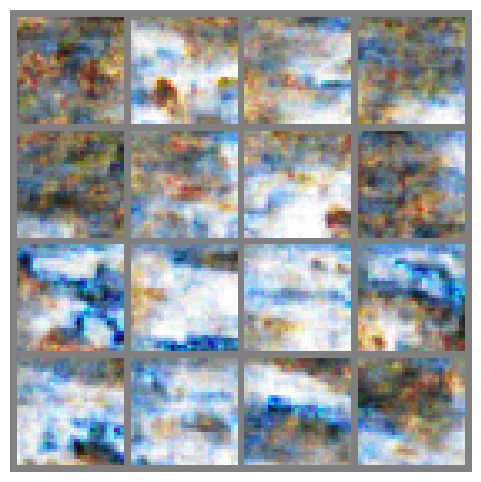

In [10]:
num_samples = 16
pl.seed_everything(1)

samples = model.sample(img_shape=(num_samples, input_channels, input_size, input_size))
show_imgs(samples.cpu())